# Batched rollouts and throughput

This notebook measures how throughput grows with
the batch, what a CUDA graph saves over launching each kernel, and how to read per-world
outcomes from a large batch.
The scene is the nut-bolt example from `viewer.scenes.nutbolt`, an M20 nut that
screws itself down its bolt under gravity.

In [1]:
import os
os.environ.setdefault("MUJOCO_GL", "egl")  # headless rendering; use "glfw" on a desktop

import time
import numpy as np
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import warp as wp

wp.config.log_level = wp.LOG_WARNING  # no init banner
wp.init()
print("device:", wp.get_device())

device: cuda:0


## Graph replay against eager stepping

`step.fwd_step(sim)` launches a step's kernels one by one. `step.make_step_graph(sim)` captures the step
once and replays it as one CUDA graph. With a few
worlds, the launches and the round trips are most of the cost and the graph removes them; with
thousands, the GPU's work dominates and the two come together.

In [2]:
import gc

from lodos import step
from viewer.scenes import nutbolt as NB

MJW = dict(contact_reduction=True, nconmax=768, njmax=3072)

def timed(fn, n=200):
    fn(); wp.synchronize()
    t0 = time.perf_counter()
    for _ in range(n):
        fn()
    wp.synchronize()
    return (time.perf_counter() - t0) / n

def within(sim):
    # The last step's contacts and rows against their capacities, and Lodos's collision's overflow flags since the start.
    return (int(sim.d.nacon.numpy()[0]) <= sim.d.naconmax and int(sim.d.nefc.numpy().max()) < sim.d.njmax
            and not sim.dcol.overflow.numpy().any())

for B in (16, 1024):
    sim = NB.build(B, nut="nut_s1.0", jitter=0.05, **MJW)
    for _ in range(240):   # 0.5 s: onto the thread
        step.fwd_step(sim)
    eager = timed(lambda: step.fwd_step(sim))
    replay = step.make_step_graph(sim)
    graph = timed(replay)
    print(f"B = {B:5d}: eager {eager * 1e3:.2f} ms/step, graph {graph * 1e3:.2f} ms/step ({eager / graph:.1f}x); "
          f"within capacities: {within(sim)}")
    del sim, replay; gc.collect()

B =    16: eager 6.73 ms/step, graph 2.02 ms/step (3.3x); within capacities: True


B =  1024: eager 9.80 ms/step, graph 7.96 ms/step (1.2x); within capacities: True


## Throughput against batch size

The unit world-s/s measures the total simulated experience (in seconds) per second of wall-clock time.

exact B =    64:   2.26 ms/step,     59.0 world-s/s; within capacities: True


exact B =   256:   3.28 ms/step,    162.8 world-s/s; within capacities: True


exact B =  1024:   7.69 ms/step,    277.5 world-s/s; within capacities: True


exact B =  4096:  29.55 ms/step,    288.7 world-s/s; within capacities: True


mj    B =    64:   0.58 ms/step,    229.1 world-s/s; within capacities: True


mj    B =   256:   0.82 ms/step,    653.7 world-s/s; within capacities: True


mj    B =  1024:   1.76 ms/step,   1212.4 world-s/s; within capacities: True


mj    B =  4096:   6.17 ms/step,   1382.8 world-s/s; within capacities: True


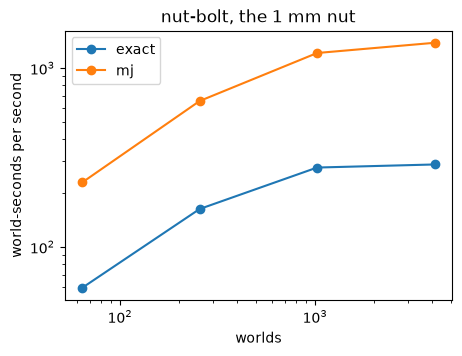

In [3]:
sizes = (64, 256, 1024, 4096)
wss = {}
for mode in ("exact", "mj"):
    wss[mode] = []
    for B in sizes:
        s = NB.build(B, nut="nut_s1.0", jitter=0.05, solver_kwargs=dict(mode=mode), **MJW)
        r = step.make_step_graph(s)
        for _ in range(240):
            r()
        ms = timed(r, 240) * 1e3
        wss[mode].append(B / (ms * 1e-3) / 480)
        print(f"{mode:5s} B = {B:5d}: {ms:6.2f} ms/step, {wss[mode][-1]:8.1f} world-s/s; within capacities: {within(s)}")
        del s, r; gc.collect()
plt.figure(figsize=(5, 3.5))
for mode in wss:
    plt.loglog(sizes, wss[mode], "o-", label=mode)
plt.xlabel("worlds"); plt.ylabel("world-seconds per second"); plt.title("nut-bolt, the 1 mm nut"); plt.legend()
plt.show()

Throughput grows with the batch up to about a thousand worlds here, and slowly beyond: the
exact mode reaches about 290 world-s/s, the mj mode about 1400, nearly five times as many.

## Per-world outcomes

2048 of 2048 nuts seated; height 0.77 mm (median), 0.65-1.05 mm (1st-99th percentile); within capacities: True


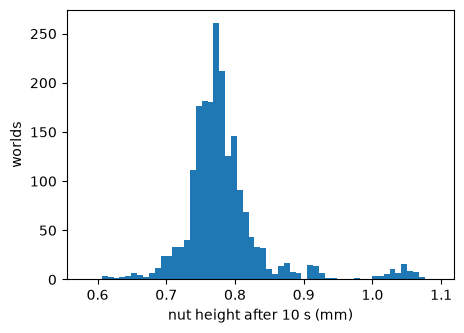

In [ ]:
# Every world starts with its nut turned a little differently (`jitter`, in radians).
sim = NB.build(2048, nut="nut_s1.0", jitter=0.05, **MJW)
replay = step.make_step_graph(sim)
hz = round(1 / NB.DT)
for _ in range(10 * hz):  # 10 s: down the thread and onto the seat
    replay()
q = sim.drbd.qpos.numpy()
z = q[:, 9] * 1e3
seated = np.isfinite(q).all(axis=1) & (z > -1) & (z < 3)
print(f"{seated.sum()} of {len(z)} nuts seated; height {np.median(z):.2f} mm (median), "
      f"{np.percentile(z, 1):.2f}-{np.percentile(z, 99):.2f} mm (1st-99th percentile); within capacities: {within(sim)}")
plt.figure(figsize=(5, 3.5)); plt.hist(z, bins=60)
plt.xlabel("nut height after 10 s (mm)"); plt.ylabel("worlds"); plt.show()

## Capacities

Lodos allocates every buffer at construction as CUDA graphs need stable addresses. `lodos.utils.calibrate.peaks` rolls a scene
forward and reports each buffer's peak demand and whether it overflowed. `calibrate.suggest` turns the report into `make_sim`
arguments with a margin.

In [5]:
from lodos.utils import calibrate

report = calibrate.peaks(sim, hz)   # one more second of the 2048 seated nuts
col = report["lodos_col"]
for stage, peak, cap in zip(col["stages"], col["peak"], col["capacity"]):
    print(f"collision stage {stage}: peak {peak:9,d} of {cap:9,d} ({100 * peak / max(cap, 1):3.0f}%)")
m = report["runtime"]
print(f"MJWarp: contacts at most {m['nacon_peak']:,} and broadphase pairs {m['ncollision_peak']:,} of {m['naconmax']:,}; "
      f"rows at most {m['nefc_peak_per_world']} of {m['njmax']} a world")
print("overflowed anywhere:", report["overflowed"])
print("suggested make_sim arguments:", calibrate.suggest(report))

collision stage nCa1: peak 8,308,024 of 38,600,704 ( 22%)
collision stage nCa2: peak 3,809,851 of 38,600,704 ( 10%)
collision stage nCa3: peak 2,257,856 of 38,600,704 (  6%)
collision stage nTa: peak 1,038,503 of 4,825,088 ( 22%)
collision stage nTb: peak         0 of 4,825,088 (  0%)
MJWarp: contacts at most 122,526 and broadphase pairs 0 of 1,572,864; rows at most 243 of 3072 a world
overflowed anywhere: False
suggested make_sim arguments: {'nconmax': 90, 'njmax': 365}


Lodos's collision stages peak at about a fifth of their capacities at most. MJWarp sees far
fewer contacts than Lodos's collision finds -- the contact reduction hands it about 60 a world of
the 1100 or so a seated nut makes -- and `suggest` sizes its capacities at 1.5 times these
peaks.